# Agent Eval Analysis

Analysis of historical agent evaluation reports.

Goals:
- track Outcome, Capability, and Grounding pass rates across runs;
- identify unstable or consistently failing eval cases;
- inspect missing evaluation data;
- prepare data for trend visualization.

## Setup

In [13]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd().parent
RUNS_DIR = PROJECT_ROOT / "reports" / "agent" / "runs"

assert RUNS_DIR.exists(), f"Reports directory not found: {RUNS_DIR}"

In [2]:
report_files = sorted(RUNS_DIR.glob("*.json"))

assert report_files, "No historical agent eval reports found"

print(f"Reports found: {len(report_files)}")

Reports found: 3


## Load and prepare historical results

Load all historical agent eval reports and convert case-level results into a single flat DataFrame.

In [3]:
run_frames = []

for report_file in report_files:
    with open(report_file, encoding="utf-8") as file:
        run_report = json.load(file)

    run_df = pd.json_normalize(run_report["results"])

    run_df = run_df[
        [
            "id",
            "outcome.passed",
            "capability.passed",
            "grounding.passed",
        ]
    ].rename(
        columns={
            "outcome.passed": "outcome",
            "capability.passed": "capability",
            "grounding.passed": "grounding",
        }
    )

    run_df["run_id"] = run_report["run_id"]
    run_df["created_at"] = run_report["created_at"]

    run_frames.append(run_df)

history_df = pd.concat(run_frames, ignore_index=True)
history_df = history_df[
    [
        "id",
        "run_id",
        "created_at",
        "outcome",
        "capability",
        "grounding",
    ]
]
history_df["created_at"] = pd.to_datetime(
    history_df["created_at"],
    utc=True,
)

In [4]:
history_df.head()

,id,run_id,created_at,outcome,capability,grounding
0,tent_price_3_days,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True
1,tent_search,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,False
2,tent_deposit,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,False
3,kyiv_delivery,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True
4,booking_rules,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True


## Data quality

Check evaluation coverage and missing values before calculating aggregate metrics.

In [5]:
metrics = ["outcome", "capability", "grounding"]
data_quality = pd.DataFrame(
    {
        "evaluated": history_df[metrics].count(),
        "missing": history_df[metrics].isna().sum(),
        "coverage": history_df[metrics].notna().mean(),
    }
).reset_index(names="metric")

data_quality.insert(1, "total", len(history_df))

data_quality

,metric,total,evaluated,missing,coverage
0,outcome,30,30,0,1.0
1,capability,30,30,0,1.0
2,grounding,30,30,0,1.0


## Run-level metrics

Calculate Outcome, Capability, and Grounding pass rates for each historical eval run.

In [6]:
run_stats = (
    history_df.groupby(["run_id", "created_at"])[["outcome", "capability", "grounding"]]
    .mean()
    .reset_index()
    .sort_values("created_at")
)

run_stats

,run_id,created_at,outcome,capability,grounding
0,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,0.9,1.0,0.8
1,20260925T203657Z_4aade3a,2026-09-25 20:36:57+00:00,0.8,1.0,0.6
2,20260929T190809Z_0d25463,2026-09-29 19:08:09+00:00,0.9,0.9,0.8


## Case-level diagnostics

Combine historical pass rates and stability indicators for each eval case.

In [7]:
case_pass_rates = (
    history_df.groupby("id")
    .agg(
        runs=("run_id", "nunique"),
        outcome=("outcome", "mean"),
        capability=("capability", "mean"),
        grounding=("grounding", "mean"),
    )
    .reset_index()
)

In [8]:
case_stability = (
    history_df.groupby("id")[["outcome", "capability", "grounding"]].nunique().reset_index()
)

In [9]:
state_columns = [f"{metric}_states" for metric in metrics]
stability_columns = [f"{metric}_stability" for metric in metrics]

stability_for_merge = case_stability.rename(
    columns={metric: f"{metric}_states" for metric in metrics}
)

case_diagnostics = case_pass_rates.merge(
    stability_for_merge,
    on="id",
)

for metric in metrics:
    case_diagnostics[f"{metric}_stability"] = case_diagnostics[f"{metric}_states"].map(
        {1: "stable", 2: "unstable"}
    )

case_diagnostics = case_diagnostics.drop(columns=state_columns)

case_diagnostics["unstable_metrics"] = (
    case_diagnostics[stability_columns].eq("unstable").sum(axis=1)
)

case_diagnostics["worst_pass_rate"] = case_diagnostics[metrics].min(axis=1)

case_diagnostics = case_diagnostics.sort_values(
    ["unstable_metrics", "worst_pass_rate"],
    ascending=[False, True],
).reset_index(drop=True)

case_diagnostics

,id,runs,outcome,capability,grounding,outcome_stability,capability_stability,grounding_stability,unstable_metrics,worst_pass_rate
0,equipment_purchase,3,0.666667,0.666667,0.666667,unstable,unstable,unstable,3,0.666667
1,equipment_cleaning,3,0.000000,1.000000,0.666667,stable,stable,unstable,1,0.000000
2,tent_search,3,1.000000,1.000000,0.333333,stable,stable,unstable,1,0.333333
3,pickup_locations,3,1.000000,1.000000,0.666667,stable,stable,unstable,1,0.666667
4,tent_deposit,3,1.000000,1.000000,0.000000,stable,stable,stable,0,0.000000
5,booking_contact,3,1.000000,1.000000,1.000000,stable,stable,stable,0,1.000000
6,booking_rules,3,1.000000,1.000000,1.000000,stable,stable,stable,0,1.000000
7,kyiv_delivery,3,1.000000,1.000000,1.000000,stable,stable,stable,0,1.000000
8,outside_kyiv_delivery,3,1.000000,1.000000,1.000000,stable,stable,stable,0,1.000000
9,tent_price_3_days,3,1.000000,1.000000,1.000000,stable,stable,stable,0,1.000000


## Run-level trends

Visualize Outcome, Capability, and Grounding pass rates across historical eval runs.

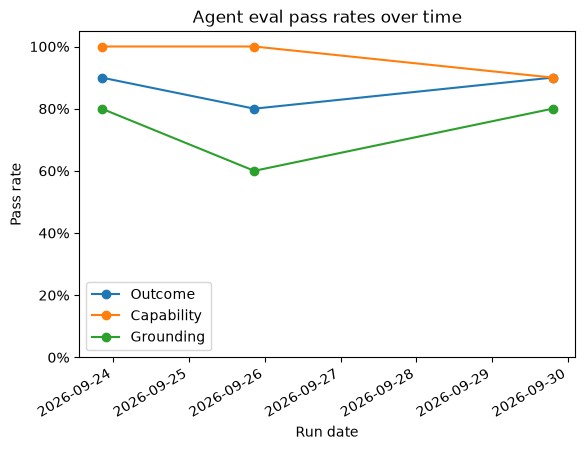

In [10]:
fig, ax = plt.subplots()

for metric in metrics:
    ax.plot(
        run_stats["created_at"],
        run_stats[metric],
        marker="o",
        label=metric.capitalize(),
    )

ax.set_title("Agent eval pass rates over time")
ax.set_xlabel("Run date")
ax.set_ylabel("Pass rate")
ax.set_ylim(0, 1.05)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()

fig.autofmt_xdate()

plt.show()

## Case-level triage

Visualize the weakest historical pass rate for each eval case.

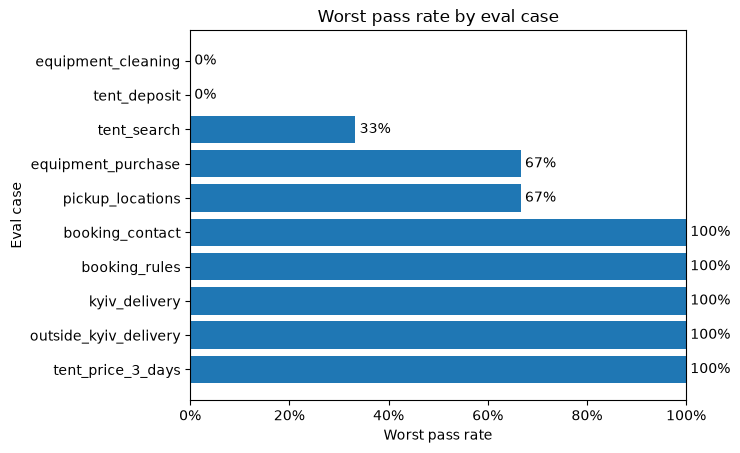

In [11]:
triage_df = case_diagnostics.sort_values("worst_pass_rate").reset_index(drop=True)

fig, ax = plt.subplots()

bars = ax.barh(
    triage_df["id"],
    triage_df["worst_pass_rate"],
)
ax.bar_label(
    bars,
    labels=[f"{value:.0%}" for value in triage_df["worst_pass_rate"]],
    padding=3,
)

ax.set_title("Worst pass rate by eval case")
ax.set_xlabel("Worst pass rate")
ax.set_ylabel("Eval case")
ax.set_xlim(0, 1)

ax.xaxis.set_major_formatter(PercentFormatter(1.0))

ax.invert_yaxis()

plt.show()

## Conclusions

In [12]:
latest_run = run_stats.iloc[-1]

unstable_case_ids = case_diagnostics.loc[
    case_diagnostics["unstable_metrics"] > 0,
    "id",
].tolist()

consistently_failing_cases = {}

for metric in metrics:
    consistently_failing_cases[metric] = case_diagnostics.loc[
        (case_diagnostics[metric] == 0) & (case_diagnostics[f"{metric}_stability"] == "stable"),
        "id",
    ].tolist()

print(f"Historical runs analyzed: {len(run_stats)}")
print(f"Latest Outcome pass rate: {latest_run['outcome']:.0%}")
print(f"Latest Capability pass rate: {latest_run['capability']:.0%}")
print(f"Latest Grounding pass rate: {latest_run['grounding']:.0%}")
print(f"Unstable cases: {', '.join(unstable_case_ids)}")

for metric, case_ids in consistently_failing_cases.items():
    print(
        f"Consistently failing {metric.capitalize()} cases: "
        + (", ".join(case_ids) if case_ids else "none")
    )

Historical runs analyzed: 3
Latest Outcome pass rate: 90%
Latest Capability pass rate: 90%
Latest Grounding pass rate: 80%
Unstable cases: equipment_purchase, equipment_cleaning, tent_search, pickup_locations
Consistently failing Outcome cases: equipment_cleaning
Consistently failing Capability cases: none
Consistently failing Grounding cases: tent_deposit
